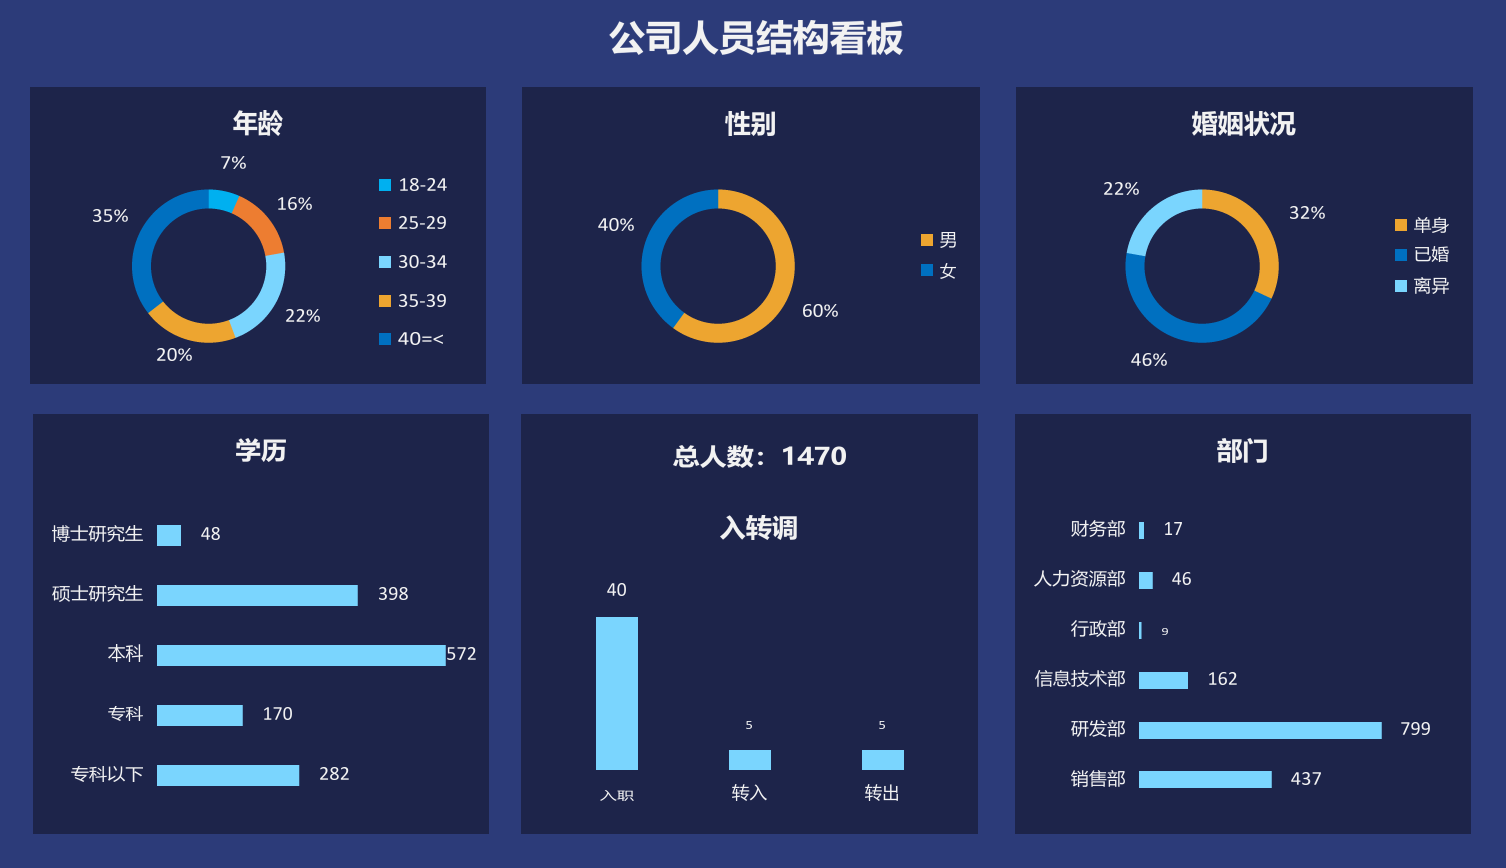

In [1]:
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
import numpy as np, zipfile, math
from IPython.display import display
RS=getattr(Image,'Resampling',Image)
S=4
FP=Path('C:/Windows/Fonts')
NS='{http://schemas.openxmlformats.org/spreadsheetml/2006/main}'
def X(p,i):
    z=zipfile.ZipFile(p); ss=[]
    if 'xl/sharedStrings.xml' in z.namelist():
        import xml.etree.ElementTree as E
        r=E.fromstring(z.read('xl/sharedStrings.xml'))
        ss=[''.join(t.text or '' for t in si.iter(NS+'t')) for si in r]
    import xml.etree.ElementTree as E
    r=E.fromstring(z.read('xl/worksheets/sheet%d.xml'%i)); d={}
    for c in r.iter(NS+'c'):
        v=c.find(NS+'v')
        if v is None or v.text is None: continue
        val=ss[int(v.text)] if c.get('t')=='s' else v.text
        d[c.get('r')]=val
    return d
def F(n,z): return ImageFont.truetype(str(FP/n),int(z))
def T(big,t,b,c=(217,217,217),bold=False):
    x0,y0,x1,y1=b[0]+5,b[1]+1,b[2]-5,b[3]-1
    if x1<=x0 or y1<=y0: return
    zh=any('\u4e00'<=q<='\u9fff' or q in '：（）·' for q in t)
    tmp=Image.new('RGBA',(4200,240),(0,0,0,0))
    ImageDraw.Draw(tmp).text((20,10),t,font=F(('msyhbd.ttc' if bold else 'msyh.ttc') if zh else ('calibrib.ttf' if bold else 'calibri.ttf'),80),fill=(*c,255))
    bb=tmp.getbbox()
    if not bb: return
    im=tmp.crop(bb).resize((max(1,(x1-x0)*S),max(1,(y1-y0)*S)),RS.LANCZOS)
    big.paste(im,(x0*S,y0*S),im)
def TXT(big,s,dc=(217,217,217)):
    for ln in s.strip().splitlines():
        p=ln.split('|'); b=[int(v) for v in p[1].split(',')]
        f=p[2] if len(p)>2 else ''
        c=tuple(bytes.fromhex(f[:6])) if len(f)>=6 else dc
        T(big,p[0],b,c,'B' in f)
def R(d,x0,y0,x1,y1,c): d.rectangle((x0*S,y0*S,(x1+1)*S-1,(y1+1)*S-1),fill=c)
def DONUT(d,cx,cy,ro,ri,segs,pc):
    bb=((cx-ro)*S,(cy-ro)*S,(cx+ro)*S,(cy+ro)*S); a=0
    for v,c in segs:
        b=a+v*360; d.pieslice(bb,a-90,b-90,fill=c); a=b
    d.ellipse(((cx-ri)*S,(cy-ri)*S,(cx+ri)*S,(cy+ri)*S),fill=pc)
def OUT(big,W,H,name):
    out=big.resize((W,H),RS.BOX); out.save(name); display(out); return out
H0=Path.home()/'Desktop/上学期/大数据分析及可视化/《Excel数据可视化 - 从图表到数据大屏》-清华-郭宏远'
hr=H0/'第四章 人力资源可视化看板.xlsx'
sa=H0/'第四章 销售看板参考.xlsx'
d1=X(hr,1) if hr.exists() else {}
d2=X(sa,5) if sa.exists() else {}
def G(d,k,v):
    try: return float(d[k])
    except: return v
N=G(d1,'N2',1470)
age=[G(d1,'K%d'%i,v) for i,v in zip(range(11,16),[97,229,325,297,522])]
sex=[G(d1,'K19',882),G(d1,'K20',588)]
mar=[G(d1,'N%d'%i,v) for i,v in zip(range(11,14),[470,673,327])]
edu=[G(d1,'K%d'%i,v) for i,v in zip(range(24,29),[282,170,572,398,48])][::-1]
dep=[G(d1,'N%d'%i,v) for i,v in zip(range(24,30),[437,799,162,9,46,17])][::-1]
mov=[G(d1,'N%d'%i,v) for i,v in zip(range(17,20),[40,5,5])]
BG1=(44,59,121); P1=(29,36,74); W1,H1=1506,868
LB=(0,176,240); OR=(237,125,49); CY=(122,213,254); GO=(237,165,48); DB=(0,112,192)
big=Image.new('RGB',(W1*S,H1*S),BG1); d=ImageDraw.Draw(big)
for b in [(30,87,485,383),(522,87,979,383),(1016,87,1472,383),(33,414,488,833),(521,414,977,833),(1015,414,1470,833)]: R(d,*b,P1)
DONUT(d,208.5,266,76.5,57.5,[(v/N,c) for v,c in zip(age,[LB,OR,CY,GO,DB])],P1)
DONUT(d,718,266,76.5,57.5,[(v/N,c) for v,c in zip(sex,[GO,DB])],P1)
DONUT(d,1202,266,76.5,57.5,[(v/N,c) for v,c in zip(mar,[GO,DB,CY])],P1)
for x,y,c in [(379,179,LB),(379,217,OR),(379,256,CY),(379,295,GO),(379,333,DB),(921,234,GO),(921,264,DB),(1395,219,GO),(1395,249,DB),(1395,280,CY)]: R(d,x,y,x+11,y+11,c)
for y,v in zip([525,585,645,705,765],edu): R(d,157,y,157+v*0.505-1,y+20,CY)
for y,v in zip([522,572,622,672,722,771],dep): R(d,1139,y,1139+v*0.304-1,y+16,CY)
for x,v in zip([596,729,862],mov): R(d,x,769-v*3.8,x+41,769,CY)
TXT(big,'''公司人员结构看板|604,19,908,56|F2F2F2B
年龄|228,109,288,137|F2F2F2B
性别|720,110,780,137|F2F2F2B
婚姻状况|1187,110,1301,137|F2F2F2B
学历|231,437,291,463|F2F2F2B
总人数：@N@|668,444,851,469|F2F2F2B
入转调|715,514,802,541|F2F2F2B
部门|1212,437,1272,464|F2F2F2B
7%|216,155,251,170
16%|273,196,317,211
22%|281,308,325,323
20%|152,347,197,362
35%|88,208,133,223
18-24|395,177,452,192
25-29|394,215,451,230
30-34|394,254,452,269
35-39|394,293,451,308
40=<|393,331,448,346
40%|593,217,639,232
60%|798,303,843,318
男|935,231,961,249
女|935,262,961,280
22%|1099,181,1144,196
32%|1285,205,1330,220
46%|1126,352,1172,367
单身|1409,216,1454,234
已婚|1410,245,1454,263
离异|1409,276,1454,295
博士研究生|47,524,148,543
48|196,526,225,541
硕士研究生|47,584,148,603
398|374,586,413,601
本科|103,643,148,663
572|442,646,481,661
专科|103,705,148,722
170|259,706,297,721
专科以下|66,765,148,783
282|315,766,354,781
财务部|1066,519,1130,538
17|1160,521,1187,536
人力资源部|1029,569,1130,588
46|1167,571,1196,586
行政部|1066,619,1130,638
9|1157,627,1173,636
信息技术部|1030,669,1130,688
162|1204,671,1242,686
研发部|1066,719,1130,738
799|1396,721,1435,736
销售部|1066,769,1130,788
437|1286,771,1326,786
40|602,582,631,597
5|741,720,757,730
5|874,720,890,730
入职|595,789,639,802
转入|727,783,772,802
转出|860,783,903,802'''.replace('@N@',str(int(N))),(242,242,242))
o1=OUT(big,W1,H1,'hr_board.png')


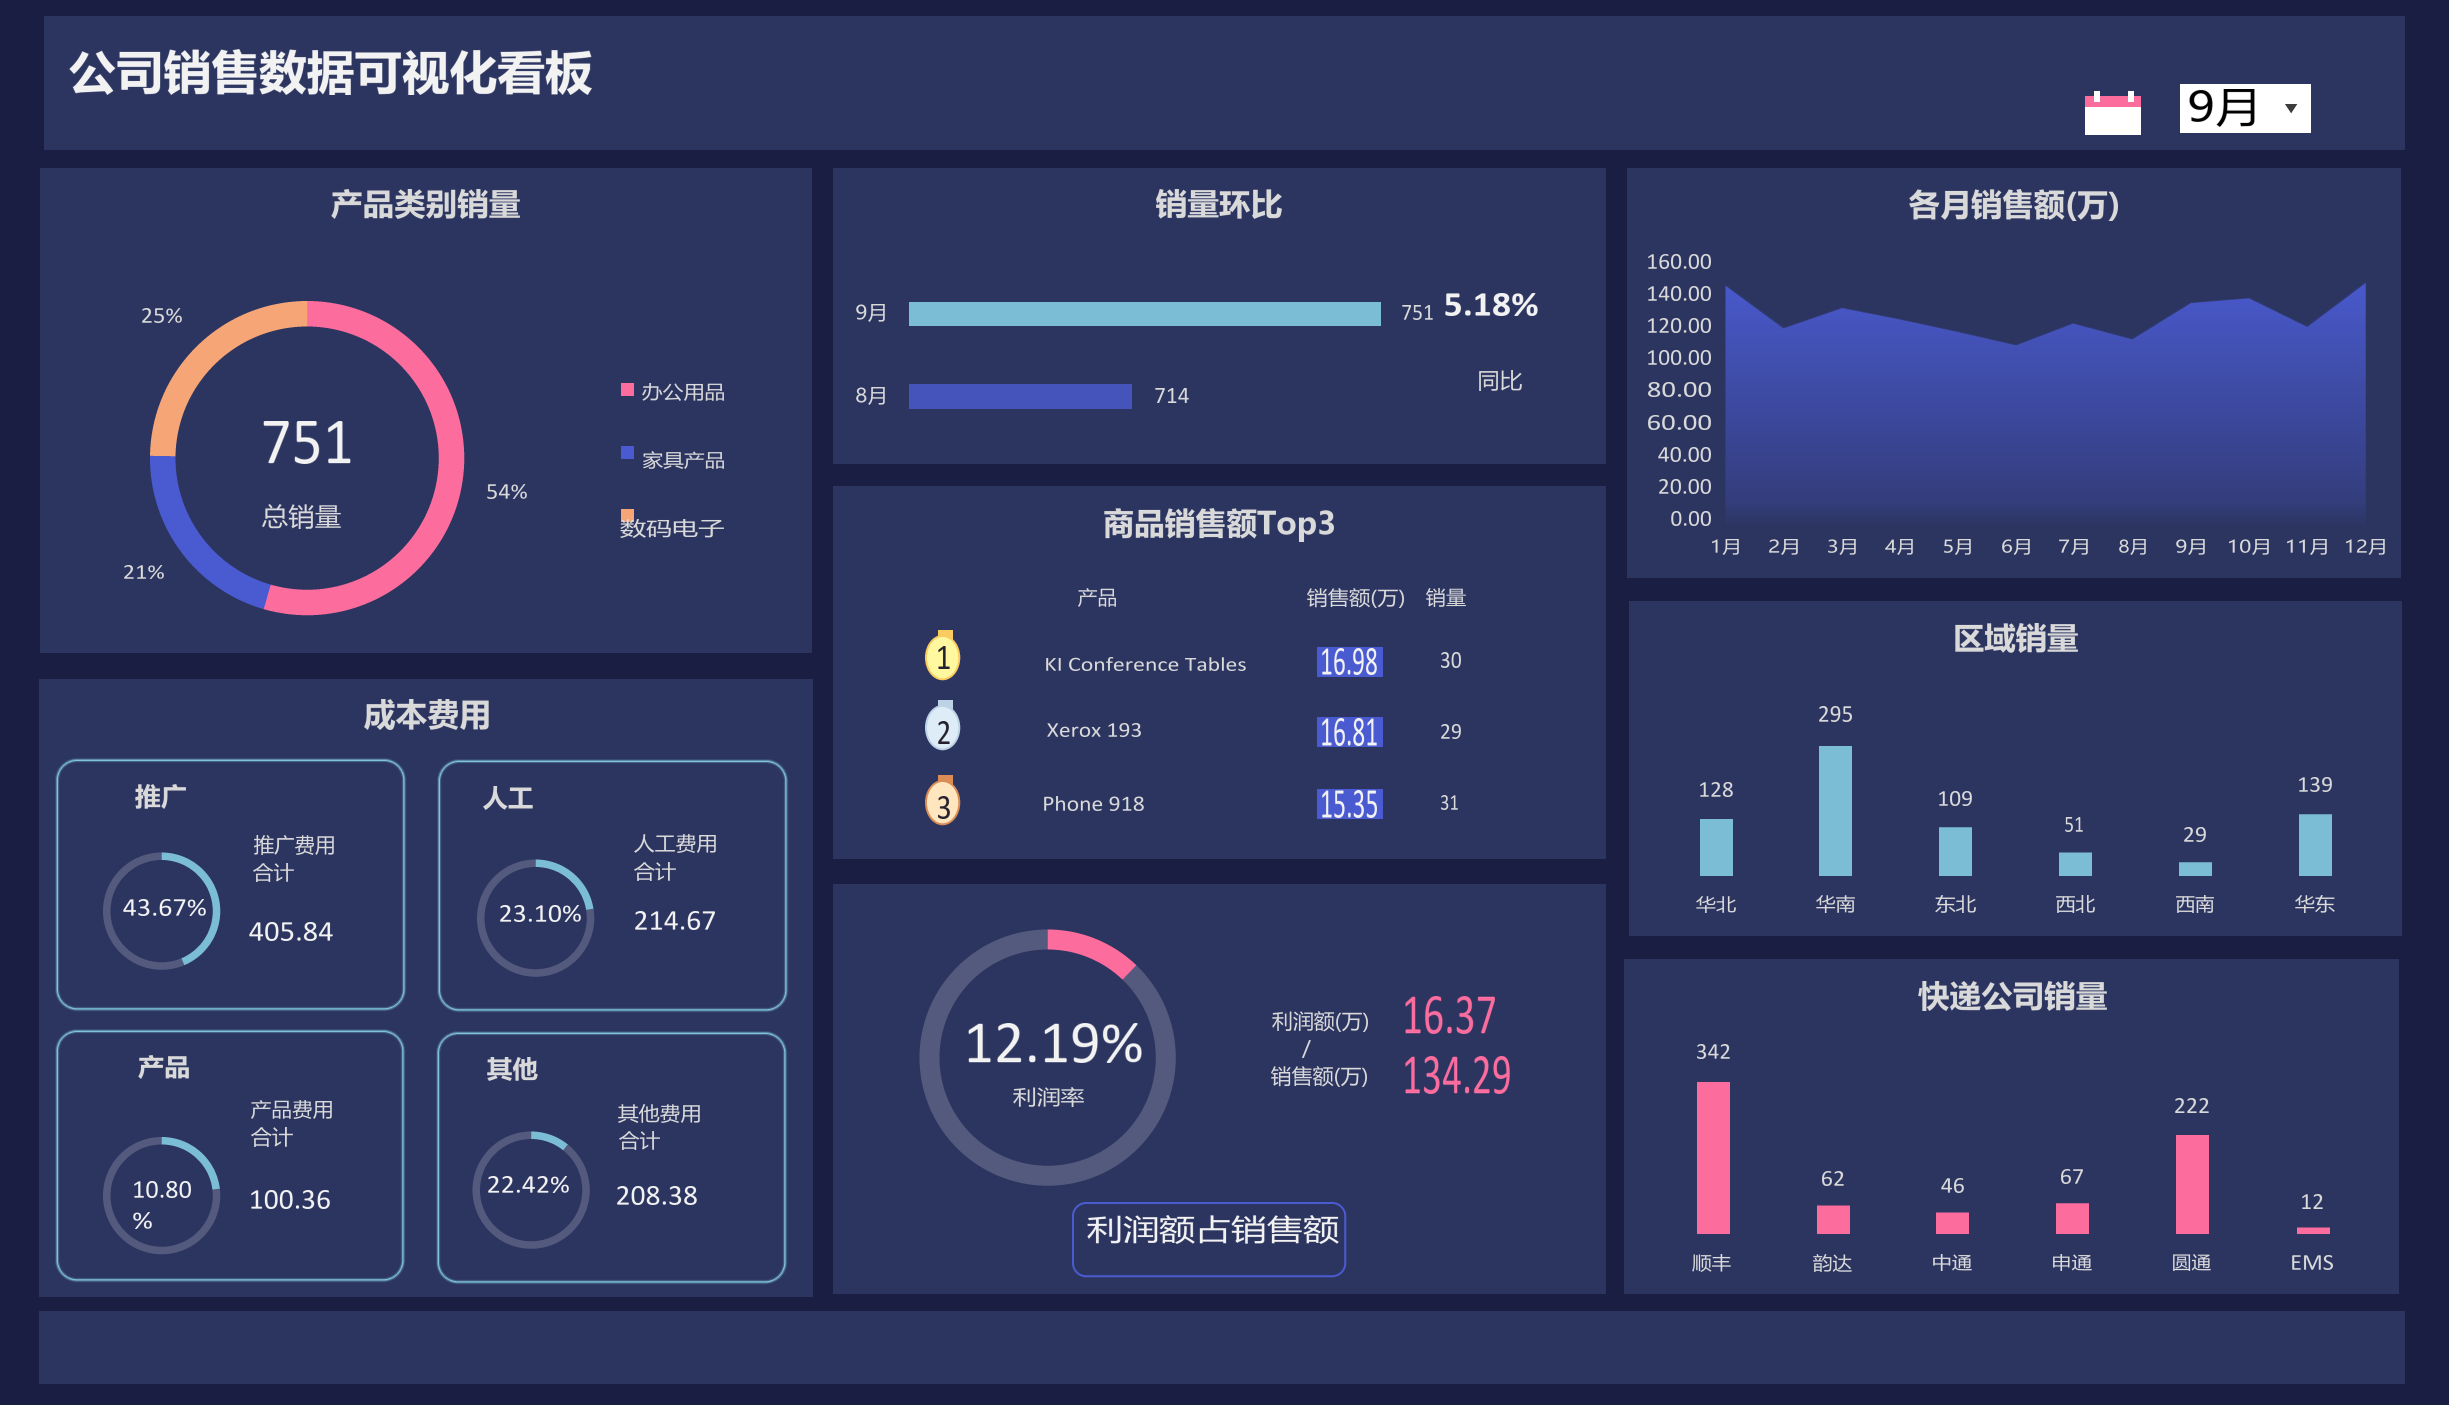

In [2]:
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
import numpy as np, zipfile, math
from IPython.display import display
RS=getattr(Image,'Resampling',Image)
S=4
FP=Path('C:/Windows/Fonts')
NS='{http://schemas.openxmlformats.org/spreadsheetml/2006/main}'
def X(p,i):
    z=zipfile.ZipFile(p); ss=[]
    if 'xl/sharedStrings.xml' in z.namelist():
        import xml.etree.ElementTree as E
        r=E.fromstring(z.read('xl/sharedStrings.xml'))
        ss=[''.join(t.text or '' for t in si.iter(NS+'t')) for si in r]
    import xml.etree.ElementTree as E
    r=E.fromstring(z.read('xl/worksheets/sheet%d.xml'%i)); d={}
    for c in r.iter(NS+'c'):
        v=c.find(NS+'v')
        if v is None or v.text is None: continue
        val=ss[int(v.text)] if c.get('t')=='s' else v.text
        d[c.get('r')]=val
    return d
def F(n,z): return ImageFont.truetype(str(FP/n),int(z))
def T(big,t,b,c=(217,217,217),bold=False):
    x0,y0,x1,y1=b[0]+5,b[1]+1,b[2]-5,b[3]-1
    if x1<=x0 or y1<=y0: return
    zh=any('\u4e00'<=q<='\u9fff' or q in '：（）·' for q in t)
    tmp=Image.new('RGBA',(4200,240),(0,0,0,0))
    ImageDraw.Draw(tmp).text((20,10),t,font=F(('msyhbd.ttc' if bold else 'msyh.ttc') if zh else ('calibrib.ttf' if bold else 'calibri.ttf'),80),fill=(*c,255))
    bb=tmp.getbbox()
    if not bb: return
    im=tmp.crop(bb).resize((max(1,(x1-x0)*S),max(1,(y1-y0)*S)),RS.LANCZOS)
    big.paste(im,(x0*S,y0*S),im)
def TXT(big,s,dc=(217,217,217)):
    for ln in s.strip().splitlines():
        p=ln.split('|'); b=[int(v) for v in p[1].split(',')]
        f=p[2] if len(p)>2 else ''
        c=tuple(bytes.fromhex(f[:6])) if len(f)>=6 else dc
        T(big,p[0],b,c,'B' in f)
def R(d,x0,y0,x1,y1,c): d.rectangle((x0*S,y0*S,(x1+1)*S-1,(y1+1)*S-1),fill=c)
def DONUT(d,cx,cy,ro,ri,segs,pc):
    bb=((cx-ro)*S,(cy-ro)*S,(cx+ro)*S,(cy+ro)*S); a=0
    for v,c in segs:
        b=a+v*360; d.pieslice(bb,a-90,b-90,fill=c); a=b
    d.ellipse(((cx-ri)*S,(cy-ri)*S,(cx+ri)*S,(cy+ri)*S),fill=pc)
def OUT(big,W,H,name):
    out=big.resize((W,H),RS.BOX); out.save(name); display(out); return out
H0=Path.home()/'Desktop/上学期/大数据分析及可视化/《Excel数据可视化 - 从图表到数据大屏》-清华-郭宏远'
hr=H0/'第四章 人力资源可视化看板.xlsx'
sa=H0/'第四章 销售看板参考.xlsx'
d1=X(hr,1) if hr.exists() else {}
d2=X(sa,5) if sa.exists() else {}
def G(d,k,v):
    try: return float(d[k])
    except: return v
q9=G(d2,'K10',751); q8=G(d2,'K9',714); yoy=G(d2,'L9',0.051820728291316565)
cat=[G(d2,'K%d'%i,v) for i,v in zip(range(13,16),[409,156,186])]
cst=[G(d2,'E%d'%i,v) for i,v in zip(range(27,31),[405.838128,208.382624,214.665924,100.36022])]
cpc=[G(d2,'F%d'%i,v) for i,v in zip(range(27,31),[0.43673875,0.224248932,0.231010644,0.1080016736])]
top=[(G(d2,'X%d'%i,''),G(d2,'Y%d'%i,v),G(d2,'Z%d'%i,v)) for i,v in zip(range(3,6),[16.98,16.81,15.35])]
amt=G(d2,'M2',16.3746218635); rev=G(d2,'K2',134.28874355); rate=G(d2,'N3',0.121935922778)
mon=[G(d2,'K%d'%i,v) for i,v in zip(range(18,30),[145.224607,118.62991245,131.26952515,124.2604812,116.50837705,108.1053584,121.61598545,111.7426972,134.28874355,137.2817269,119.55373105,146.8738222])]
reg=[G(d2,'E%d'%i,v) for i,v in zip(range(9,15),[128,295,109,51,29,139])]
exp=[G(d2,'E%d'%i,v) for i,v in zip(range(18,24),[342,62,46,67,222,12])]
BG2=(26,30,67); P2=(44,53,96); W2,H2=2449,1405
PK=(252,108,157); PU=(74,91,209); OC=(246,165,118); TQ=(123,189,213); GY=(83,90,125); BR=(101,151,183)
big=Image.new('RGB',(W2*S,H2*S),BG2); d=ImageDraw.Draw(big)
for b in [(44,16,2404,149),(40,168,811,652),(39,679,812,1296),(833,168,1605,463),(833,486,1605,858),(833,884,1605,1293),(1627,168,2400,577),(1629,601,2401,935),(1624,959,2398,1293),(39,1311,2404,1383)]: R(d,*b,P2)
R(d,2180,84,2310,132,(255,255,255)); R(d,2085,96,2140,134,(255,255,255)); R(d,2085,96,2140,106,(252,108,157))
for x in [2094,2128]: R(d,x,91,x+5,101,(255,255,255))
d.polygon([(2285*S,104*S),(2297*S,104*S),(2291*S,113*S)],fill=(60,60,60))
DONUT(d,307,458,157,131.5,[(v/sum(cat),c) for v,c in zip(cat,[PK,PU,OC])],P2)
for x,y,c in [(621,383,PK),(621,446,PU),(621,509,OC)]: R(d,x,y,x+12,y+12,c)
for i,(x0,y0,x1,y1) in enumerate([(55,758,406,1011),(437,759,788,1012),(55,1029,405,1282),(436,1031,787,1284)]):
    for k,c in enumerate([(57,75,115),(94,138,169),(127,196,221),(70,97,134),(48,59,101)]):
        d.rounded_rectangle(((x0+k)*S,(y0+k)*S,(x1-k)*S,(y1-k)*S),radius=(22-k)*S,outline=c,width=S)
for (cx,cy),p in zip([(161.5,911),(535.5,918),(161.5,1195.5),(531,1190)],cpc):
    DONUT(d,cx,cy,58.5,51,[(p,TQ),(1-p,GY)],P2)
R(d,909,302,1380,325,TQ); R(d,909,384,1131,408,(68,84,186))
for y in [647,717,789]: R(d,1317,y,1382,y+29,PU)
for i,(y,fc,ec) in enumerate([(635,(255,248,159),(250,204,96)),(705,(221,236,247),(190,210,230)),(780,(255,230,191),(220,140,87))]):
    R(d,938,y-5,952,y+5,ec)
    d.ellipse((925*S,y*S,960*S,(y+45)*S),fill=fc,outline=ec,width=2*S)
DONUT(d,1047.5,1057.5,128,108,[(rate,PK),(1-rate,GY)],P2)
d.rounded_rectangle((1072*S,1202*S,1346*S,1277*S),radius=14*S,outline=PU,width=2*S)
xs=[1725.5,1783.5,1842,1899,1957,2016,2073,2132,2190.5,2249,2307,2365.5]
ys=[518.5-1.607*v for v in mon]
x0,y0,x1,y1=1700,250,2395,528
ml=Image.new('L',((x1-x0)*S,(y1-y0)*S),0)
ImageDraw.Draw(ml).polygon([((x-x0)*S,(y-y0)*S) for x,y in zip(xs,ys)]+[((xs[-1]-x0)*S,(527-y0)*S),((xs[0]-x0)*S,(527-y0)*S)],fill=255)
w,h=(x1-x0)*S,(y1-y0)*S
ya=np.arange(h)/S+y0
cc=np.zeros((h,3)); m=ya<=500
cc[m]=np.array([73,89,203])-np.outer(ya[m]-285,[0.098,0.125,0.36])
t=(ya[~m]-500)/27
cc[~m]=np.stack([52-8*t,63-10*t,126-30*t],1)
arr=np.repeat(np.clip(cc,0,255).astype(np.uint8)[:,None,:],w,axis=1)
big.paste(Image.fromarray(arr),(x0*S,y0*S),ml)
d.line([(x*S,y*S) for x,y in zip(xs,ys)],fill=(48,59,117),width=S)
for x,v in zip([1700,1819,1939,2059,2179,2299],reg):
    R(d,x,875-0.437*v,x+32,875,TQ)
for x,v in zip([1697,1817,1936,2056,2176,2297],exp):
    R(d,x,1233-0.441*v,x+32,1233,PK)
TXT(big,'''公司销售数据可视化看板|64,48,597,96|F2F2F2B
产品类别销量|326,188,525,220|D9D9D9B
销量环比|1151,188,1287,220|D9D9D9B
各月销售额(万)|1904,188,2123,222|D9D9D9B
成本费用|359,698,494,731|D9D9D9B
商品销售额Top3|1099,507,1339,543|D9D9D9B
区域销量|1950,622,2083,654|D9D9D9B
快递公司销量|1913,980,2112,1012|D9D9D9B
9月|2184,88,2260,128|000000
25%|137,307,187,324
54%|482,483,532,500
21%|119,564,169,580
751|258,420,356,465|F2F2F2
总销量|257,503,346,530
办公用品|637,382,729,402
家具产品|638,450,729,470
数码电子|615,518,729,539
9月|851,303,890,323
8月|851,386,890,406
751|1397,304,1438,321
5.18%|1440,292,1543,317|F2F2F2B
714|1150,387,1194,404
同比|1474,369,1527,392
产品|1073,587,1121,608
销售额(万)|1302,587,1409,609
销量|1421,587,1471,608
KI Conference Tables|1041,656,1251,672
Xerox 193|1042,722,1146,738
Phone 918|1039,795,1149,812
16.98|1317,647,1382,676|F2F2F2
16.81|1317,717,1382,747|F2F2F2
15.35|1317,789,1382,819|F2F2F2
30|1436,651,1466,669
29|1436,723,1466,740
31|1436,794,1463,811
1|933,645,955,670|25202D
2|933,720,955,745|25202D
3|933,795,955,820|25202D
12.19%|963,1022,1147,1064|F2F2F2
利润率|1008,1086,1089,1108
利润额(万)|1267,1010,1373,1033
/|1297,1039,1316,1059
销售额(万)|1266,1065,1372,1088
16.37|1400,995,1500,1035|FC6C9D
134.29|1400,1055,1515,1095|FC6C9D
利润额占销售额|1082,1214,1344,1245|F2F2F2
推广|130,783,191,810|D9D9D9B
人工|478,785,538,811|D9D9D9B
产品|133,1054,194,1080|D9D9D9B
其他|482,1056,543,1082|D9D9D9B
推广费用|249,834,339,856
合计|248,862,299,883
人工费用|629,833,721,854
合计|629,861,681,882
产品费用|246,1099,337,1120
合计|246,1126,298,1148
其他费用|613,1103,705,1124
合计|614,1130,665,1151
43.67%|118,898,211,917|F2F2F2
23.10%|495,904,586,923|F2F2F2
10.80|129,1180,196,1199|F2F2F2
%|128,1211,157,1230|F2F2F2
22.42%|483,1175,574,1194|F2F2F2
405.84|244,921,338,942|F2F2F2
214.67|630,910,720,931|F2F2F2
100.36|246,1189,335,1210|F2F2F2
208.38|612,1185,702,1206|F2F2F2
160.00|1643,253,1716,270
140.00|1643,285,1716,302
120.00|1643,317,1716,334
100.00|1643,349,1716,366
80.00|1643,381,1716,398
60.00|1643,414,1716,431
40.00|1653,446,1716,463
20.00|1654,478,1716,495
0.00|1666,510,1716,527
1月|1707,538,1744,556
2月|1764,538,1803,556
3月|1823,538,1861,556
4月|1880,538,1918,556
5月|1939,538,1976,556
6月|1997,538,2035,556
7月|2054,538,2093,556
8月|2114,538,2151,556
9月|2171,538,2210,556
10月|2224,538,2274,556
11月|2282,538,2332,556
12月|2341,538,2390,556
128|1695,781,1738,798
295|1814,705,1857,723
109|1934,790,1977,807
51|2060,816,2088,833
29|2179,826,2211,843
139|2294,776,2337,793
华北|1691,895,1741,914
华南|1811,894,1860,914
东北|1930,894,1981,914
西北|2051,894,2100,914
西南|2171,894,2219,914
华东|2290,894,2340,914
342|1692,1043,1735,1060
62|1817,1170,1849,1187
46|1936,1177,1969,1194
67|2056,1168,2088,1185
222|2170,1097,2214,1114
12|2297,1193,2328,1210
顺丰|1687,1253,1736,1273
韵达|1808,1253,1857,1273
中通|1928,1253,1977,1272
申通|2048,1253,2097,1272
圆通|2168,1253,2216,1272
EMS|2287,1254,2338,1271''')
o2=OUT(big,W2,H2,'sales_board.png')
